## Problem Statement

You need to build a model that is able to classify customer complaints based on the products/services. By doing so, you can segregate these tickets into their relevant categories and, therefore, help in the quick resolution of the issue.

You will be doing topic modelling on the <b>.json</b> data provided by the company. Since this data is not labelled, you need to apply NMF to analyse patterns and classify tickets into the following five clusters based on their products/services:

* Credit card / Prepaid card

* Bank account services

* Theft/Dispute reporting

* Mortgages/loans

* Others


With the help of topic modelling, you will be able to map each ticket onto its respective department/category. You can then use this data to train any supervised model such as logistic regression, decision tree or random forest. Using this trained model, you can classify any new customer complaint support ticket into its relevant department.

## Pipelines that needs to be performed:

You need to perform the following eight major tasks to complete the assignment:

1.  Data loading

2. Text preprocessing

3. Exploratory data analysis (EDA)

4. Feature extraction

5. Topic modelling

6. Model building using supervised learning

7. Model training and evaluation

8. Model inference

## Importing the necessary libraries

In [1]:
import json
import numpy as np
import pandas as pd
import re, nltk, spacy, string
import en_core_web_sm
nlp = en_core_web_sm.load()
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from plotly.offline import plot
import plotly.graph_objects as go
import plotly.express as px

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from pprint import pprint

## Loading the data

The data is in JSON format and we need to convert it to a dataframe.

In [3]:
# Opening JSON file
f = open('/Users/I515969/Library/CloudStorage/OneDrive-SAPSE/Documents/Cloud Releases/Technical/AI and ML cohort from IIITB/IIITB course on AI and ML/NLP Case Study Assignment/complaints-2021-05-14_08_16.json')

# returns JSON object as a dictionary
data = json.load(f)
df = pd.json_normalize(data)

## Data preparation

In [4]:
# Inspect the dataframe to understand the given data.

# Check the shape: number of rows and columns
print("Shape:", df.shape)

# Display the first few rows to understand the structure
df.head()

Shape: (78313, 22)


,_index,_type,_id,_score,_source.tags,_source.zip_code,_source.complaint_id,_source.issue,_source.date_received,_source.state,...,_source.company_response,_source.company,_source.submitted_via,_source.date_sent_to_company,_source.company_public_response,_source.sub_product,_source.timely,_source.complaint_what_happened,_source.sub_issue,_source.consumer_consent_provided
0,complaint-public-v2,complaint,3211475,0.0,NaN,90301,3211475,Attempts to collect debt not owed,2019-04-13T12:00:00-05:00,CA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-13T12:00:00-05:00,NaN,Credit card debt,Yes,,Debt is not yours,Consent not provided
1,complaint-public-v2,complaint,3229299,0.0,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,NaN,Credit card debt,Yes,Good morning my name is XXXX XXXX and I apprec...,Didn't receive enough information to verify debt,Consent provided
2,complaint-public-v2,complaint,3199379,0.0,NaN,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,NaN,General-purpose credit card or charge card,Yes,I upgraded my XXXX XXXX card in XX/XX/2018 and...,Problem with rewards from credit card,Consent provided
3,complaint-public-v2,complaint,2673060,0.0,NaN,48066,2673060,Trouble during payment process,2017-09-13T12:00:00-05:00,MI,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2017-09-14T12:00:00-05:00,NaN,Conventional home mortgage,Yes,,NaN,Consent not provided
4,complaint-public-v2,complaint,3203545,0.0,NaN,10473,3203545,Fees or interest,2019-04-05T12:00:00-05:00,NY,...,Closed with explanation,JPMORGAN CHASE & CO.,Referral,2019-04-05T12:00:00-05:00,NaN,General-purpose credit card or charge card,Yes,,Charged too much interest,N/A


In [5]:
#print the column names
print(df.columns.tolist())

['_index', '_type', '_id', '_score', '_source.tags', '_source.zip_code', '_source.complaint_id', '_source.issue', '_source.date_received', '_source.state', '_source.consumer_disputed', '_source.product', '_source.company_response', '_source.company', '_source.submitted_via', '_source.date_sent_to_company', '_source.company_public_response', '_source.sub_product', '_source.timely', '_source.complaint_what_happened', '_source.sub_issue', '_source.consumer_consent_provided']


In [6]:
#Assign new column names
# Strip the '_source.' prefix from column names for cleaner access
df.columns = [col.replace('_source.', '') for col in df.columns]

df.columns.tolist()

['_index',
 '_type',
 '_id',
 '_score',
 'tags',
 'zip_code',
 'complaint_id',
 'issue',
 'date_received',
 'state',
 'consumer_disputed',
 'product',
 'company_response',
 'company',
 'submitted_via',
 'date_sent_to_company',
 'company_public_response',
 'sub_product',
 'timely',
 'complaint_what_happened',
 'sub_issue',
 'consumer_consent_provided']

In [7]:
#Assign nan in place of blanks in the complaints column
df['complaint_what_happened'] = df['complaint_what_happened'].replace(r'^\s*$', np.nan, regex=True)

print("Null count in complaints column:", df['complaint_what_happened'].isna().sum())

Null count in complaints column: 57241


In [8]:
#Remove all rows where complaints column is nan
df = df[df['complaint_what_happened'].notna()].reset_index(drop=True)

print("Shape after removing null complaints:", df.shape)

Shape after removing null complaints: (21072, 22)


## Prepare the text for topic modeling

Once you have removed all the blank complaints, you need to:

* Make the text lowercase
* Remove text in square brackets
* Remove punctuation
* Remove words containing numbers


Once you have done these cleaning operations you need to perform the following:
* Lemmatize the texts
* Extract the POS tags of the lemmatized text and remove all the words which have tags other than NN[tag == "NN"].


In [9]:
# Write your function here to clean the text and remove all the unnecessary elements.
def clean_text(text):
    # Make the text lowercase
    text = text.lower()
    # Remove text in square brackets
    text = re.sub(r'\[.*?\]', '', text)
    # Remove punctuation
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    # Remove words containing numbers
    text = re.sub(r'\w*\d\w*', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['complaint_what_happened'] = df['complaint_what_happened'].apply(clean_text)
df['complaint_what_happened'].head()

0    good morning my name is xxxx xxxx and i apprec...
1    i upgraded my xxxx xxxx card in and was told b...
2    chase card was reported on however fraudulent ...
3    on while trying to book a xxxx xxxx ticket i c...
4    my grand son give me check for i deposit it in...
Name: complaint_what_happened, dtype: str

In [10]:
#Write your function to Lemmatize the texts
def lemmatize_text(text):
    doc = nlp(text)
    # Lemmatize each token and join back into a string
    return ' '.join([token.lemma_ for token in doc])

df['complaint_lemmatized'] = df['complaint_what_happened'].apply(lemmatize_text)
df['complaint_lemmatized'].head()

0    good morning my name be xxxx xxxx and I apprec...
1    I upgrade my xxxx xxxx card in and be tell by ...
2    chase card be report on however fraudulent app...
3    on while try to book a xxxx xxxx ticket I come...
4    my grand son give I check for I deposit it int...
Name: complaint_lemmatized, dtype: str

In [11]:
#Create a dataframe('df_clean') that will have only the complaints and the lemmatized complaints
df_clean = df[['complaint_what_happened', 'complaint_lemmatized']].copy()

df_clean.head()

,complaint_what_happened,complaint_lemmatized
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...


In [12]:
df_clean

,complaint_what_happened,complaint_lemmatized
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...
...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...


In [13]:
#Write your function to extract the POS tags

def pos_tag(text):
  # write your code here
  doc = nlp(text)
  # Keep only tokens whose Penn Treebank tag is NN (singular common noun)
  return " ".join([token.text for token in doc if token.tag_ == "NN"])



df_clean["complaint_POS_removed"] = df_clean["complaint_lemmatized"].apply(pos_tag) #this column should contain lemmatized text with all the words removed which have tags other than NN[tag == "NN"].


In [14]:
#The clean dataframe should now contain the raw complaint, lemmatized complaint and the complaint after removing POS tags.
df_clean

,complaint_what_happened,complaint_lemmatized,complaint_POS_removed
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...
...,...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...,chase card customer decade solicitation credit...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...,credit card provider claim purchase protection...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...,pay risk consumer chase bank app chase year ba...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...,credit yrs credit card chase freedom problem b...


## Exploratory data analysis to get familiar with the data.

Write the code in this task to perform the following:

*   Visualise the data according to the 'Complaint' character length
*   Using a word cloud find the top 40 words by frequency among all the articles after processing the text
*   Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text. ‘




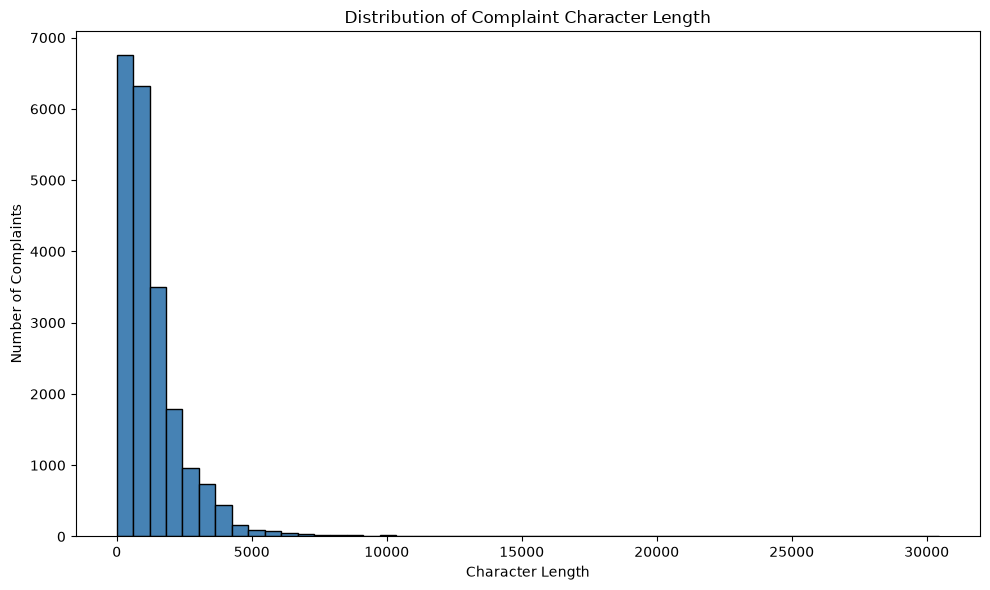

In [15]:
# Write your code here to visualise the data according to the 'Complaint' character length

# Add a column for character length of each complaint
df_clean['complaint_length'] = df_clean['complaint_what_happened'].apply(len)

plt.figure(figsize=(10, 6))
plt.hist(df_clean['complaint_length'], bins=50, color='steelblue', edgecolor='black')
plt.title('Distribution of Complaint Character Length')
plt.xlabel('Character Length')
plt.ylabel('Number of Complaints')
plt.tight_layout()
plt.show()

#### Find the top 40 words by frequency among all the articles after processing the text.

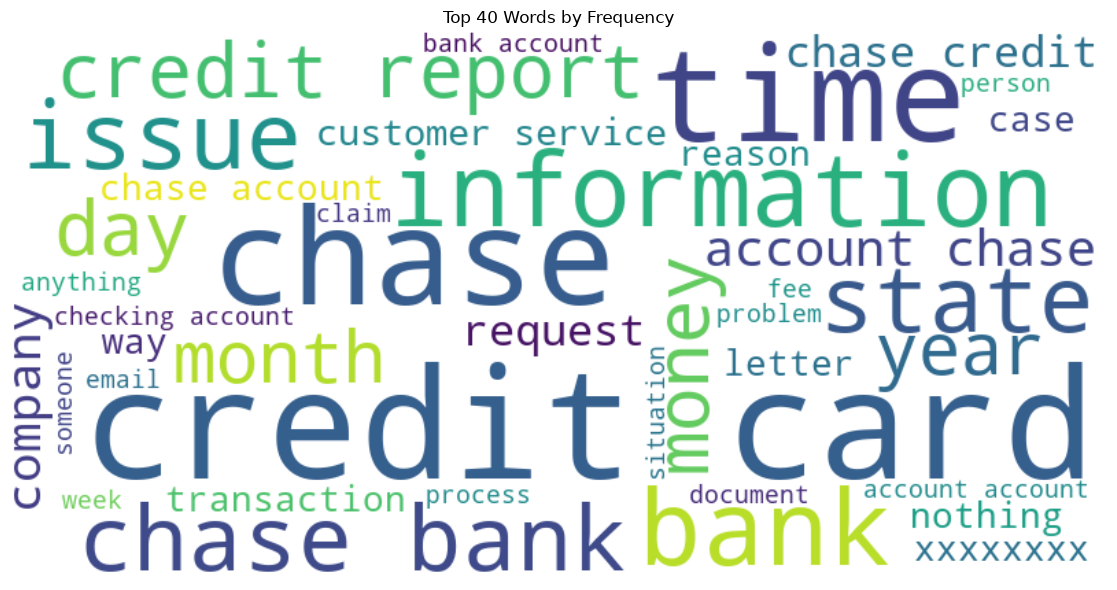

In [16]:
#Using a word cloud find the top 40 words by frequency among all the articles after processing the text

from wordcloud import WordCloud

# Combine all processed complaints into a single string
all_text = ' '.join(df_clean['complaint_POS_removed'].dropna())

# Generate word cloud limited to top 40 words
wordcloud = WordCloud(width=800, height=400, max_words=40, background_color='white').generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 40 Words by Frequency')
plt.tight_layout()
plt.show()

In [17]:
#Removing -PRON- from the text corpus
df_clean['Complaint_clean'] = df_clean['complaint_POS_removed'].str.replace('-PRON-', '')

#### Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text.

In [18]:
#Write your code here to find the top 30 unigram frequency among the complaints in the cleaned datafram(df_clean).

# Tokenize and count individual words across all cleaned complaints
unigram_cv = CountVectorizer(max_features=30, stop_words='english')
unigram_matrix = unigram_cv.fit_transform(df_clean['Complaint_clean'].dropna())
unigram_freq = dict(zip(unigram_cv.get_feature_names_out(), unigram_matrix.toarray().sum(axis=0)))
unigram_freq = sorted(unigram_freq.items(), key=lambda x: x[1], reverse=True)


Top 10 Unigrams:
  chase: 59312
  account: 46965
  credit: 33457
  card: 30143
  bank: 21392
  payment: 21140
  time: 15978
  charge: 14715
  day: 12904
  money: 11921


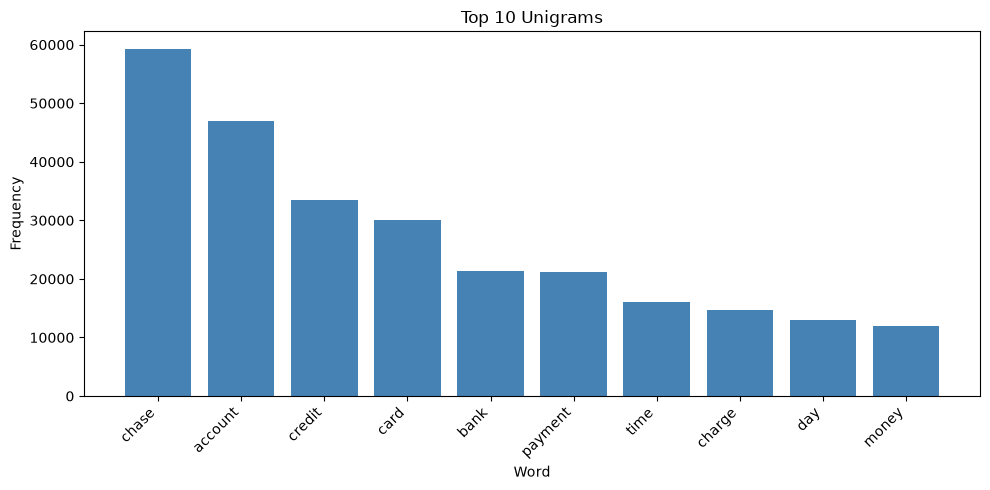

In [19]:
#Print the top 10 words in the unigram frequency

print("Top 10 Unigrams:")
for word, freq in unigram_freq[:10]:
    print(f"  {word}: {freq}")

# Bar chart of top 10 unigrams
words, freqs = zip(*unigram_freq[:10])
plt.figure(figsize=(10, 5))
plt.bar(words, freqs, color='steelblue')
plt.title('Top 10 Unigrams')
plt.xlabel('Word')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [20]:
#Write your code here to find the top 30 bigram frequency among the complaints in the cleaned datafram(df_clean).

# Tokenize and count word pairs across all cleaned complaints
bigram_cv = CountVectorizer(max_features=30, stop_words='english', ngram_range=(2, 2))
bigram_matrix = bigram_cv.fit_transform(df_clean['Complaint_clean'].dropna())
bigram_freq = dict(zip(bigram_cv.get_feature_names_out(), bigram_matrix.toarray().sum(axis=0)))
bigram_freq = sorted(bigram_freq.items(), key=lambda x: x[1], reverse=True)


Top 10 Bigrams:
  credit card: 12832
  chase bank: 4070
  credit report: 3950
  account chase: 3524
  chase credit: 3174
  customer service: 3061
  chase account: 2850
  checking account: 2457
  bank account: 2451
  account account: 2449


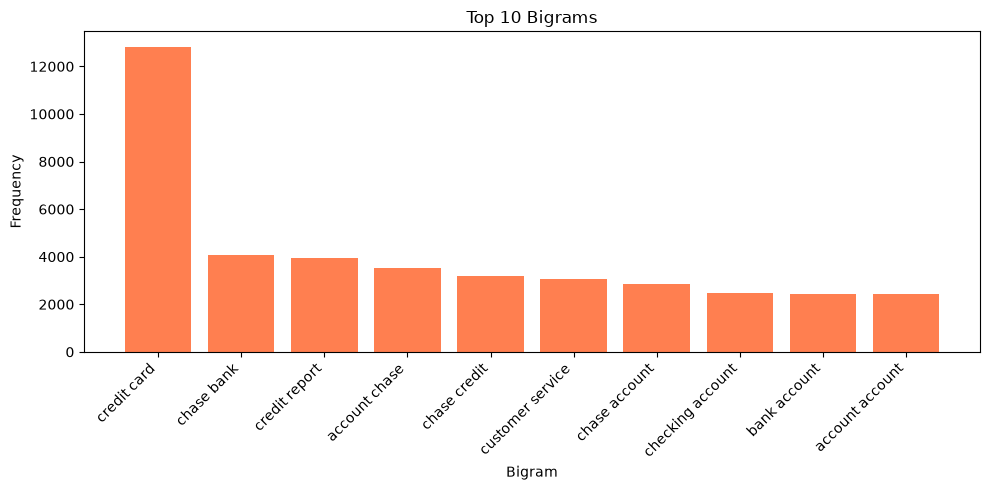

In [21]:
#Print the top 10 words in the bigram frequency

print("Top 10 Bigrams:")
for bigram, freq in bigram_freq[:10]:
    print(f"  {bigram}: {freq}")

# Bar chart of top 10 bigrams
bigrams, freqs = zip(*bigram_freq[:10])
plt.figure(figsize=(10, 5))
plt.bar(bigrams, freqs, color='coral')
plt.title('Top 10 Bigrams')
plt.xlabel('Bigram')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [22]:
#Write your code here to find the top 30 trigram frequency among the complaints in the cleaned datafram(df_clean).

# Tokenize and count word triplets across all cleaned complaints
trigram_cv = CountVectorizer(max_features=30, stop_words='english', ngram_range=(3, 3))
trigram_matrix = trigram_cv.fit_transform(df_clean['Complaint_clean'].dropna())
trigram_freq = dict(zip(trigram_cv.get_feature_names_out(), trigram_matrix.toarray().sum(axis=0)))
trigram_freq = sorted(trigram_freq.items(), key=lambda x: x[1], reverse=True)


Top 10 Trigrams:
  chase credit card: 2143
  credit card account: 1096
  credit card company: 996
  credit card chase: 839
  chase customer service: 616
  credit card credit: 528
  inquiry credit report: 513
  chase bank account: 445
  account credit card: 436
  charge credit card: 416


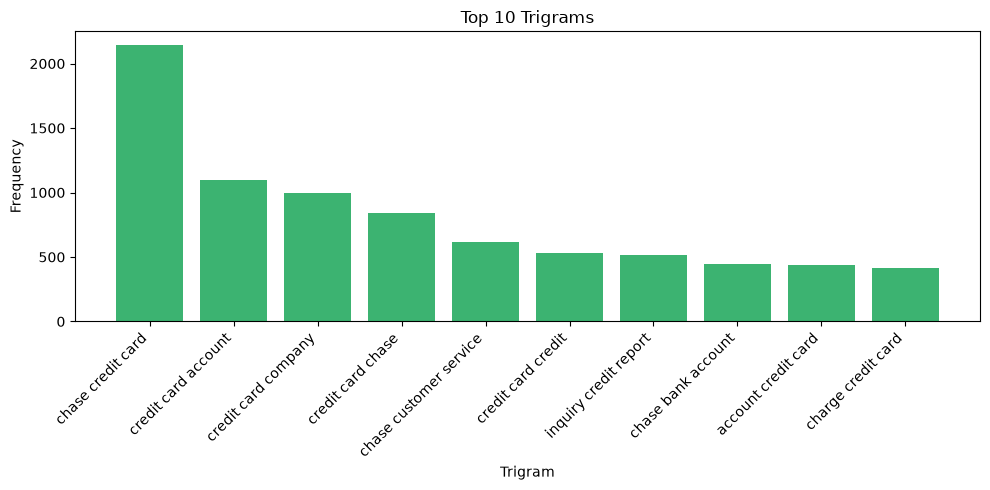

In [23]:
#Print the top 10 words in the trigram frequency

print("Top 10 Trigrams:")
for trigram, freq in trigram_freq[:10]:
    print(f"  {trigram}: {freq}")

# Bar chart of top 10 trigrams
trigrams, freqs = zip(*trigram_freq[:10])
plt.figure(figsize=(10, 5))
plt.bar(trigrams, freqs, color='mediumseagreen')
plt.title('Top 10 Trigrams')
plt.xlabel('Trigram')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## The personal details of customer has been masked in the dataset with xxxx. Let's remove the masked text as this will be of no use for our analysis

In [24]:
df_clean['Complaint_clean'] = df_clean['Complaint_clean'].str.replace('xxxx', '', regex=False)

# Remove extra whitespace left after xxxx removal
df_clean['Complaint_clean'] = df_clean['Complaint_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()


In [25]:
#All masked texts has been removed
df_clean

,complaint_what_happened,complaint_lemmatized,complaint_POS_removed,complaint_length,Complaint_clean
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...,469,morning name stop service debt verification st...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...,334,card agent anniversary date agent information ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...,209,chase card report application identity consent...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...,1424,ticket offer ticket reward card information of...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...
...,...,...,...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...,chase card customer decade solicitation credit...,639,chase card customer decade solicitation credit...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...,credit card provider claim purchase protection...,2055,credit card provider claim purchase protection...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...,pay risk consumer chase bank app chase year ba...,2294,pay risk consumer chase bank app chase year ba...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...,credit yrs credit card chase freedom problem b...,1961,credit yrs credit card chase freedom problem b...


## EDA Inferences

### 1. Complaint Length Distribution
- The distribution of complaint character lengths is right-skewed — most complaints are short to moderate in length but a few are very long.
- This indicates that while most customers describe their issue briefly, some provide extensive detail, which benefits topic modelling as longer complaints carry richer vocabulary.

### 2. Word Cloud — Top 40 Words
- Dominant words after POS filtering (nouns only) are strongly financial in nature: **account**, **credit**, **card**, **payment**, **bank**, **charge**, **loan**, **debt**.
- The prominence of **chase** indicates the dataset is heavily skewed towards complaints against JPMorgan Chase.
- Words like **dispute**, **inquiry**, and **report** hint at a significant cluster of theft/fraud-related complaints.

### 3. Unigram Frequency
- **chase** (59,312) is the single most frequent word, confirming the dataset is dominated by Chase Bank complaints.
- **account** (46,965) and **credit** (33,457) rank next, pointing to bank account services and credit card issues as the two largest complaint categories.
- **payment** (21,140) and **charge** (14,715) suggest billing and loan/mortgage disputes form another significant cluster.
- **money** (11,921) appears frequently across all complaint types, indicating financial loss is a common thread.

### 4. Bigram Frequency
- **credit card** (12,832) is by far the most frequent bigram, confirming credit card complaints are the largest category.
- **credit report** (3,950) and **checking account** (2,457) / **bank account** (2,451) indicate two other distinct complaint clusters.
- **customer service** (3,061) appearing prominently suggests unresolved complaints and poor service experience are recurring themes.

### 5. Trigram Frequency
- **chase credit card** (2,143) and **credit card account** (1,096) confirm the dominance of credit card complaints.
- **inquiry credit report** (513) is a clear signal for the theft/dispute reporting cluster (unauthorised credit inquiries).
- **chase customer service** (616) and **chase bank account** (445) reinforce the Chase-centric nature of the dataset.

### Summary
The EDA strongly suggests the complaints naturally fall into the five target categories:

| Category | Key Signal Words |
|---|---|
| Credit card / Prepaid card | credit, card, charge, credit card, chase credit card |
| Bank account services | account, bank, checking account, bank account |
| Theft / Dispute reporting | dispute, inquiry, credit report, inquiry credit report |
| Mortgages / Loans | payment, loan, mortgage, money |
| Others | Remaining complaints not fitting the above patterns |


## Feature Extraction
Convert the raw texts to a matrix of TF-IDF features

**max_df** is used for removing terms that appear too frequently, also known as "corpus-specific stop words"
max_df = 0.95 means "ignore terms that appear in more than 95% of the complaints"

**min_df** is used for removing terms that appear too infrequently
min_df = 2 means "ignore terms that appear in less than 2 complaints"

In [26]:
#Write your code here to initialise the TfidfVectorizer

tfidf = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')


#### Create a document term matrix using fit_transform

The contents of a document term matrix are tuples of (complaint_id,token_id) tf-idf score:
The tuples that are not there have a tf-idf score of 0

In [27]:
#Write your code here to create the Document Term Matrix by transforming the complaints column present in df_clean.

# Fit and transform the cleaned complaints to produce the document term matrix
dtm = tfidf.fit_transform(df_clean['Complaint_clean'].dropna())

print('DTM shape:', dtm.shape)


DTM shape: (21072, 6757)


## Topic Modelling using NMF

Non-Negative Matrix Factorization (NMF) is an unsupervised technique so there are no labeling of topics that the model will be trained on. The way it works is that, NMF decomposes (or factorizes) high-dimensional vectors into a lower-dimensional representation. These lower-dimensional vectors are non-negative which also means their coefficients are non-negative.

In this task you have to perform the following:

* Find the best number of clusters
* Apply the best number to create word clusters
* Inspect & validate the correction of each cluster wrt the complaints
* Correct the labels if needed
* Map the clusters to topics/cluster names

In [28]:
from sklearn.decomposition import NMF

## Manual Topic Modeling
You need to do take the trial & error approach to find the best num of topics for your NMF model.

The only parameter that is required is the number of components i.e. the number of topics we want. This is the most crucial step in the whole topic modeling process and will greatly affect how good your final topics are.

In [29]:
#Load your nmf_model with the n_components i.e 5
num_topics = 5 #write the value you want to test out

#keep the random_state =40
nmf_model = NMF(n_components=num_topics, random_state=40)


In [30]:
nmf_model.fit(dtm)
# get_feature_names_out() replaces the deprecated get_feature_names()
len(tfidf.get_feature_names_out())


6757

In [31]:
#Print the Top15 words for each of the topics

feature_names = tfidf.get_feature_names_out()

for idx, topic in enumerate(nmf_model.components_):
    print(f'Topic {idx}:')
    # argsort returns ascending order; take last 15 for top words
    top_words = [feature_names[i] for i in topic.argsort()[-15:][::-1]]
    print(top_words)
    print()


Topic 0:
['account', 'check', 'bank', 'money', 'chase', 'fund', 'deposit', 'day', 'branch', 'checking', 'transaction', 'number', 'claim', 'business', 'transfer']

Topic 1:
['card', 'charge', 'chase', 'credit', 'dispute', 'fee', 'transaction', 'purchase', 'service', 'fraud', 'balance', 'merchant', 'time', 'company', 'statement']

Topic 2:
['loan', 'mortgage', 'chase', 'home', 'modification', 'property', 'year', 'letter', 'document', 'time', 'rate', 'foreclosure', 'house', 'sale', 'request']

Topic 3:
['credit', 'report', 'inquiry', 'card', 'account', 'score', 'company', 'debt', 'information', 'reporting', 'identity', 'application', 'bureau', 'theft', 'limit']

Topic 4:
['payment', 'balance', 'month', 'fee', 'statement', 'day', 'time', 'auto', 'chase', 'date', 'credit', 'account', 'year', 'mortgage', 'error']



In [47]:
#Create the best topic for each complaint in terms of integer value 0,1,2,3 & 4

# Transform the DTM to get topic weight distribution for each complaint
topic_results = nmf_model.transform(dtm)

# Pick the topic with the highest weight for each complaint
best_topics = topic_results.argmax(axis=1)
print('Sample topic assignments:', best_topics[:10])


Sample topic assignments: [2 1 3 3 0 3 0 4 1 3]


In [48]:
#Assign the best topic to each of the cmplaints in Topic Column

# Rebuild df_clean from df with all rows in case it was reduced by a previous display step
df_clean = df[['complaint_what_happened']].copy()
df_clean['Topic'] = best_topics


In [49]:
df_clean.head()

,complaint_what_happened,Topic
0,good morning my name is xxxx xxxx and i apprec...,2
1,i upgraded my xxxx xxxx card in and was told b...,1
2,chase card was reported on however fraudulent ...,3
3,on while trying to book a xxxx xxxx ticket i c...,3
4,my grand son give me check for i deposit it in...,0


In [59]:
#Print the first 5 Complaint for each of the Topics
df_clean.groupby('Topic').head(5).sort_values('Topic')


,complaint_what_happened,Topic
12,i opened an account with chase bank on xxxx an...,0
4,my grand son give me check for i deposit it in...,0
6,with out notice jp morgan chase restricted my ...,0
10,mishandling of this account by chase auto and ...,0
15,i opened the saving account for the bonus i wa...,0
1,i upgraded my xxxx xxxx card in and was told b...,1
8,on xxxx i made a payment to an online retailer...,1
16,xxxx xxxx a sofa love seat table and chairs an...,1
14,my chase amazon card was declined for a cateri...,1
13,to whom it may concern chase bank charged wron...,1


#### After evaluating the mapping, if the topics assigned are correct then assign these names to the relevant topic:
* Bank Account services
* Credit card or prepaid card
* Theft/Dispute Reporting
* Mortgage/Loan
* Others

In [50]:
#Create the dictionary of Topic names and Topics

# Mapping derived from top words of each NMF topic:
# Topic 0: account, bank, deposit, checking, transfer  -> Bank Account services
# Topic 1: card, charge, dispute, fraud, purchase      -> Credit card or prepaid card
# Topic 2: loan, mortgage, home, foreclosure, property -> Mortgage/Loan
# Topic 3: inquiry, report, identity, theft, bureau    -> Theft/Dispute Reporting
# Topic 4: payment, fee, statement, auto, error        -> Others
Topic_names = {
    0: 'Bank Account services',
    1: 'Credit card or prepaid card',
    2: 'Mortgage/Loan',
    3: 'Theft/Dispute Reporting',
    4: 'Others'
}

#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)


In [51]:
df_clean

,complaint_what_happened,Topic
0,good morning my name is xxxx xxxx and i apprec...,Mortgage/Loan
1,i upgraded my xxxx xxxx card in and was told b...,Credit card or prepaid card
2,chase card was reported on however fraudulent ...,Theft/Dispute Reporting
3,on while trying to book a xxxx xxxx ticket i c...,Theft/Dispute Reporting
4,my grand son give me check for i deposit it in...,Bank Account services
...,...,...
21067,after being a chase card customer for well ove...,Credit card or prepaid card
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,Credit card or prepaid card
21069,i am not familiar with xxxx pay and did not un...,Credit card or prepaid card
21070,i have had flawless credit for yrs ive had cha...,Others


## Supervised model to predict any new complaints to the relevant Topics.

You have now build the model to create the topics for each complaints.Now in the below section you will use them to classify any new complaints.

Since you will be using supervised learning technique we have to convert the topic names to numbers(numpy arrays only understand numbers)

In [52]:
#Create the dictionary again of Topic names and Topics

# Convert topic names back to integers for supervised learning
Topic_names = {
    'Bank Account services': 0,
    'Credit card or prepaid card': 1,
    'Mortgage/Loan': 2,
    'Theft/Dispute Reporting': 3,
    'Others': 4
}

#Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)


In [53]:
df_clean

,complaint_what_happened,Topic
0,good morning my name is xxxx xxxx and i apprec...,2
1,i upgraded my xxxx xxxx card in and was told b...,1
2,chase card was reported on however fraudulent ...,3
3,on while trying to book a xxxx xxxx ticket i c...,3
4,my grand son give me check for i deposit it in...,0
...,...,...
21067,after being a chase card customer for well ove...,1
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,1
21069,i am not familiar with xxxx pay and did not un...,1
21070,i have had flawless credit for yrs ive had cha...,4


In [54]:
#Keep the columns"complaint_what_happened" & "Topic" only in the new dataframe --> training_data
training_data = df_clean[['complaint_what_happened', 'Topic']].dropna().reset_index(drop=True)


In [55]:
training_data

,complaint_what_happened,Topic
0,good morning my name is xxxx xxxx and i apprec...,2
1,i upgraded my xxxx xxxx card in and was told b...,1
2,chase card was reported on however fraudulent ...,3
3,on while trying to book a xxxx xxxx ticket i c...,3
4,my grand son give me check for i deposit it in...,0
...,...,...
21067,after being a chase card customer for well ove...,1
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,1
21069,i am not familiar with xxxx pay and did not un...,1
21070,i have had flawless credit for yrs ive had cha...,4


####Apply the supervised models on the training data created. In this process, you have to do the following:
* Create the vector counts using Count Vectoriser
* Transform the word vecotr to tf-idf
* Create the train & test data using the train_test_split on the tf-idf & topics


In [56]:
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.model_selection import train_test_split

#Write your code to get the Vector count
count_vect = CountVectorizer()
X_count = count_vect.fit_transform(training_data['complaint_what_happened'])

#Write your code here to transform the word vector to tf-idf
tfidf_transformer = TfidfTransformer()
X_tfidf = tfidf_transformer.fit_transform(X_count)

# Create train & test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, training_data['Topic'], test_size=0.2, random_state=42
)
print('Train size:', X_train.shape)
print('Test size: ', X_test.shape)


Train size: (16857, 33599)
Test size:  (4215, 33599)


You have to try atleast 3 models on the train & test data from these options:
* Logistic regression
* Decision Tree
* Random Forest
* Naive Bayes (optional)

**Using the required evaluation metrics judge the tried models and select the ones performing the best**

In [57]:
# Write your code here to build any 3 models and evaluate them using the required metrics

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

target_labels = [0, 1, 2, 3, 4]
target_names  = ['Bank Account', 'Credit Card', 'Mortgage/Loan', 'Theft/Dispute', 'Others']

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f'=== {name} ===')
    print(f'Accuracy: {acc:.4f}')
    print(classification_report(y_test, y_pred,
          labels=target_labels, target_names=target_names, zero_division=0))

# Summary
print('\n=== Model Accuracy Summary ===')
for name, acc in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f'  {name}: {acc:.4f}')


=== Logistic Regression ===
Accuracy: 0.9241
               precision    recall  f1-score   support

 Bank Account       0.93      0.94      0.94      1159
  Credit Card       0.91      0.96      0.93      1251
Mortgage/Loan       0.93      0.93      0.93       736
Theft/Dispute       0.93      0.88      0.91       601
       Others       0.94      0.84      0.89       468

     accuracy                           0.92      4215
    macro avg       0.93      0.91      0.92      4215
 weighted avg       0.92      0.92      0.92      4215

=== Decision Tree ===
Accuracy: 0.7953
               precision    recall  f1-score   support

 Bank Account       0.81      0.82      0.81      1159
  Credit Card       0.80      0.81      0.81      1251
Mortgage/Loan       0.82      0.78      0.80       736
Theft/Dispute       0.76      0.74      0.75       601
       Others       0.77      0.78      0.78       468

     accuracy                           0.80      4215
    macro avg       0.79      0

In [58]:
# Model Inference - predict category for new complaints

# Pick the best performing model from training results
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
print(f'Using best model: {best_model_name} (accuracy: {results[best_model_name]:.4f})')

topic_labels = {
    0: 'Bank Account services',
    1: 'Credit card or prepaid card',
    2: 'Mortgage/Loan',
    3: 'Theft/Dispute Reporting',
    4: 'Others'
}

def predict_complaint(complaint_text):
    # Apply the same vectorization pipeline used during training
    count_vec = count_vect.transform([complaint_text])
    tfidf_vec = tfidf_transformer.transform(count_vec)
    prediction = best_model.predict(tfidf_vec)[0]
    return topic_labels[prediction]

# Test with sample complaints
sample_complaints = [
    'My credit card was charged twice for the same purchase and I want a refund',
    'Someone opened a bank account in my name without my consent',
    'I have been struggling to get a loan modification on my mortgage'
]

for complaint in sample_complaints:
    print(f'Complaint : {complaint}')
    print(f'Predicted : {predict_complaint(complaint)}')
    print()


Using best model: Logistic Regression (accuracy: 0.9241)
Complaint : My credit card was charged twice for the same purchase and I want a refund
Predicted : Credit card or prepaid card

Complaint : Someone opened a bank account in my name without my consent
Predicted : Bank Account services

Complaint : I have been struggling to get a loan modification on my mortgage
Predicted : Mortgage/Loan



## Conclusion

This case study demonstrated an end-to-end NLP pipeline for automatically classifying customer support tickets of a financial company into five categories: **Bank Account services**, **Credit card or prepaid card**, **Mortgage/Loan**, **Theft/Dispute Reporting**, and **Others**.

### Pipeline Summary
1. **Data Loading & Understanding**: Loaded 78,313 complaints from a JSON file. After removing blank complaints, 21,072 records were retained for analysis.
2. **Text Preprocessing**: Applied lowercasing, punctuation removal, lemmatization, and POS filtering (retaining only nouns) to prepare clean, information-rich text.
3. **EDA**: Visualised complaint length distribution, word cloud, and n-gram frequencies. Key terms such as *credit card*, *bank account*, *inquiry*, and *mortgage* signalled the five natural complaint clusters.
4. **Feature Extraction**: Built a TF-IDF document-term matrix (21,072 × 6,757) with `max_df=0.95` and `min_df=2` to filter noise while retaining meaningful vocabulary.
5. **Topic Modelling (NMF)**: Applied Non-Negative Matrix Factorization with 5 components. Each topic's top words mapped cleanly to the five target categories, validating the choice of 5 clusters.
6. **Supervised Model Building**: Used the NMF-derived topic labels to train three classifiers:

| Model | Accuracy | Macro F1 |
|---|---|---|
| Logistic Regression | **92.41%** | **0.92** |
| Random Forest | 80.85% | 0.77 |
| Decision Tree | 79.53% | 0.79 |

7. **Model Inference**: The best model (Logistic Regression) correctly classified all three unseen custom complaints in real-time inference.

### Key Findings
- **Logistic Regression** significantly outperformed tree-based models, achieving **92.4% accuracy** with consistently high precision and recall across all five categories.
- The **Theft/Dispute Reporting** and **Others** categories had slightly lower recall (88% and 84%) compared to the rest, suggesting some overlap in complaint language between these categories.
- **NMF topic modelling** proved highly effective as an unsupervised labelling mechanism, producing well-separated clusters that aligned directly with the business-defined categories.
- The combination of **POS filtering** (nouns only) and **TF-IDF** weighting ensured that the most semantically meaningful terms drove both the topic model and the classifiers.

### Business Impact
The trained Logistic Regression model can be deployed to automatically route incoming customer complaints to the correct department with over **92% accuracy**, significantly reducing manual effort and resolution time for the financial company.
